# Run SDM for Snowdon Beetle (*Chrysolina cerealis*)

*Section 11 — Case study: species distribution modelling, notebook 2 of 2.* Previous: `01_prepare_datasets`. Next: `12_downloading_data/01_dwnld_usgs_landsat_scenes`.

Now you have prepared the data layers, the next stage is to run the Species Distribution Modelling (SDM) with the `rsgispy.modelling.species_distribution` module and a scikit-learn logistic regression.

**You will learn:**
- how to generate pseudo-absences and extract the environmental variables for presences and absences;
- how to explore and select variables (box plots, correlation matrix) and standardise them;
- how to tune, fit and interpret a model (grid search, ROC/AUC with `plot_roc_curve`, jackknife variable importance, response curves, Sobol sensitivity analysis);
- how to predict an ensemble of models to create SDM maps.

**Before you start:** run `01_prepare_datasets` (it creates the sightings layer, study area mask and habitat distance images in `outputs/`). Classification is introduced in section 4 (`04_image_classification`).

**Data:** `outputs/Chrysolina_cerealis_osgb.gpkg`, `outputs/Study_Area.tif` and `outputs/phase1_dist_imgs/*.tif` from notebook 01; `../data/sdm/environmental_data/Elevation.tif` and `Mean_Winter_Temp.tif`.

**Run time:** about 1 minute.

> **RSGISLib users:** the RSGISLib tutorial used a stand-alone `species_distribution.py` module; its functions are now part of rsgispy as `rsgispy.modelling.species_distribution` (`salib_sklearn_mdl_sensitity` is spelt `salib_sklearn_mdl_sensitivity` and the `calc_img_stats` argument of the prediction functions is `calc_stats`).

## Import Modules

In [1]:
import glob
import importlib.util
import os
import warnings

import geopandas
import matplotlib.pyplot as plt
import rsgispy
import rsgispy.mapping.raster
import rsgispy.modelling.species_distribution as species_distribution
import rsgispy.tools.files
import rsgispy.tools.jsonio
import rsgispy.tools.plotting
import rsgispy.vector.io
import rsgispy.vector.selection
from IPython.display import Image, display
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV

%matplotlib inline

# scikit-learn 1.8 deprecates the 'penalty' argument of LogisticRegression
# (in favour of 'l1_ratio'); hide those warnings so the outputs are readable.
warnings.filterwarnings("ignore", message=".*penalty.*")

## Create Output Data Directories

GeoTIFF outputs are compressed (DEFLATE) by default in rsgispy, so no environment set-up is needed.

In [2]:
out_dir = "outputs/sdm_LogReg_outs"
os.makedirs(out_dir, exist_ok=True)
tmp_dir = "outputs/tmp_dir"
os.makedirs(tmp_dir, exist_ok=True)

## Define Input Data Files

In [3]:
# Sighting (Presence) Data
presence_sightings_vec_file = "outputs/Chrysolina_cerealis_osgb.gpkg"
presence_sightings_vec_lyr = "Chrysolina_cerealis_osgb"

# ROI Mask Image
study_site_msk_img = "outputs/Study_Area.tif"

# Environmental Images:
elevation_img = "../data/sdm/environmental_data/Elevation.tif"
winter_temp_img = "../data/sdm/environmental_data/Mean_Winter_Temp.tif"
dist_phase1_imgs = sorted(glob.glob("outputs/phase1_dist_imgs/*.tif"))

## 1. Create Pseudo Absences

We only have presence records, so pseudo-absences are randomly sampled within the study area (`n_smpls`, from `xtra_n_smpls` candidates), rejecting any within 250 m of a presence. A random seed is set so the results are repeatable.

In [4]:
pseudo_absences_vec_lyr = "pseudo_absences"
pseudo_absences_vec_file = os.path.join(out_dir, f"{pseudo_absences_vec_lyr}.gpkg")
species_distribution.gen_pseudo_absences_smpls(
    in_msk_img=study_site_msk_img,
    img_msk_val=1,
    out_vec_file=pseudo_absences_vec_file,
    out_vec_lyr=pseudo_absences_vec_lyr,
    n_smpls=1000,
    xtra_n_smpls=5000,
    presence_smpls_vec_file=presence_sightings_vec_file,
    presence_smpls_vec_lyr=presence_sightings_vec_lyr,
    presence_smpls_dist_thres=250,
    out_format="GPKG",
    rnd_seed=42,
    use_pbar=False,
)

## 2. Create the dictionary of Environmental Variables

In [5]:
env_vars = dict()
env_vars["elevation"] = species_distribution.EnvVarInfo(
    name="elevation",
    file=elevation_img,
    band=1,
    data_type=rsgispy.VAR_TYPE_CONTINUOUS,
    min_vld_val=0,
    max_vld_val=2500,
)
env_vars["winter temperature"] = species_distribution.EnvVarInfo(
    name="winter temperature",
    file=winter_temp_img,
    band=1,
    data_type=rsgispy.VAR_TYPE_CONTINUOUS,
    min_vld_val=0,
    max_vld_val=10,
)
# Loop through the distance images and create the EnvVarInfo
# objects for each distance image.
for dist_img in dist_phase1_imgs:
    dist_basename = rsgispy.tools.files.get_file_basename(dist_img)
    dist_name = dist_basename.replace("_", " ").lower()
    print(f"{dist_img}: {dist_name}")
    env_vars[dist_name] = species_distribution.EnvVarInfo(
        name=dist_name,
        file=dist_img,
        band=1,
        data_type=rsgispy.VAR_TYPE_CONTINUOUS,
        min_vld_val=0,
        max_vld_val=20000,
    )

outputs/phase1_dist_imgs/Acidneutral_flush_dist.tif: acidneutral flush dist
outputs/phase1_dist_imgs/Acidneutral_rock_dist.tif: acidneutral rock dist
outputs/phase1_dist_imgs/Acidneutral_scree_dist.tif: acidneutral scree dist
outputs/phase1_dist_imgs/Amenity_grassland_dist.tif: amenity grassland dist
outputs/phase1_dist_imgs/Bare_ground_dist.tif: bare ground dist
outputs/phase1_dist_imgs/Bare_peat_dist.tif: bare peat dist
outputs/phase1_dist_imgs/Basic_dry_heathcalcareous_grassland_mosaic_dist.tif: basic dry heathcalcareous grassland mosaic dist
outputs/phase1_dist_imgs/Basin_mire_dist.tif: basin mire dist
outputs/phase1_dist_imgs/Blanket_bog_dist.tif: blanket bog dist
outputs/phase1_dist_imgs/Bracken_dist.tif: bracken dist
outputs/phase1_dist_imgs/Brophyte_dominated_spring_dist.tif: brophyte dominated spring dist
outputs/phase1_dist_imgs/Buildings_dist.tif: buildings dist
outputs/phase1_dist_imgs/Dense_scrub_dist.tif: dense scrub dist
outputs/phase1_dist_imgs/Dry_acid_heath_dist.tif: 

In [6]:
analysis_vars = list()
for var in env_vars:
    analysis_vars.append(env_vars[var].name)
analysis_vars

['elevation',
 'winter temperature',
 'acidneutral flush dist',
 'acidneutral rock dist',
 'acidneutral scree dist',
 'amenity grassland dist',
 'bare ground dist',
 'bare peat dist',
 'basic dry heathcalcareous grassland mosaic dist',
 'basin mire dist',
 'blanket bog dist',
 'bracken dist',
 'brophyte dominated spring dist',
 'buildings dist',
 'dense scrub dist',
 'dry acid heath dist',
 'dry modified bog dist',
 'ephemeralshort perennial dist',
 'fen dist',
 'flush and spring dist',
 'gardens dist',
 'improved grassland dist',
 'lichenbryophyte heath dist',
 'marshy grassland juncus dominated dist',
 'marshy grassland molinia dominated dist',
 'marshy grassland dist',
 'natural rock exposure dist',
 'non ruderal herb and fern dist',
 'other rock exposure dist',
 'planted broadleaved woodland dist',
 'planted coniferous woodland dist',
 'quarry dist',
 'running water dist',
 'scree dist',
 'semi improved acid grassland dist',
 'semi improved neutral grassland dist',
 'semi natural b

## 3. Extract Image Data Values for Sighting Data

In [7]:
presence_env_var_vec_lyr = "Chrysolina_cerealis_osgb_env_vars"
presence_env_var_vec_file = os.path.join(out_dir, f"{presence_env_var_vec_lyr}.gpkg")
species_distribution.extract_env_var_data(
    env_vars=env_vars,
    smpls_vec_file=presence_sightings_vec_file,
    smpls_vec_lyr=presence_sightings_vec_lyr,
    out_vec_file=presence_env_var_vec_file,
    out_vec_lyr=presence_env_var_vec_lyr,
    out_format="GPKG",
    out_no_data_val=-9999,
    replace=True,
    use_pbar=False,
)

In [8]:
absences_env_var_vec_lyr = "pseudo_absences_env_var"
absences_env_var_vec_file = os.path.join(out_dir, f"{absences_env_var_vec_lyr}.gpkg")
species_distribution.extract_env_var_data(
    env_vars=env_vars,
    smpls_vec_file=pseudo_absences_vec_file,
    smpls_vec_lyr=pseudo_absences_vec_lyr,
    out_vec_file=absences_env_var_vec_file,
    out_vec_lyr=absences_env_var_vec_lyr,
    out_format="GPKG",
    out_no_data_val=-9999,
    replace=True,
    use_pbar=False,
)

Remove any points which have invalid values (-9999) for any of the environmental variables.

In [9]:
drop_atts = {var: -9999 for var in analysis_vars}

presence_env_var_vld_vec_lyr = "Chrysolina_cerealis_osgb_env_vars_vld"
presence_env_var_vld_vec_file = os.path.join(
    out_dir, f"{presence_env_var_vld_vec_lyr}.gpkg"
)
rsgispy.vector.selection.drop_rows_by_multi_attributes(
    vec_file=presence_env_var_vec_file,
    vec_lyr=presence_env_var_vec_lyr,
    drop_atts=drop_atts,
    out_vec_file=presence_env_var_vld_vec_file,
    out_vec_lyr=presence_env_var_vld_vec_lyr,
    out_format="GPKG",
    del_exist_vec=True,
)

absences_env_var_vld_vec_lyr = "pseudo_absences_env_var_vld"
absences_env_var_vld_vec_file = os.path.join(
    out_dir, f"{absences_env_var_vld_vec_lyr}.gpkg"
)
rsgispy.vector.selection.drop_rows_by_multi_attributes(
    vec_file=absences_env_var_vec_file,
    vec_lyr=absences_env_var_vec_lyr,
    drop_atts=drop_atts,
    out_vec_file=absences_env_var_vld_vec_file,
    out_vec_lyr=absences_env_var_vld_vec_lyr,
    out_format="GPKG",
    del_exist_vec=True,
)

## 4. How Many Samples Are Left?

In [10]:
n_presence_pts = rsgispy.vector.io.get_vec_feat_count(
    presence_env_var_vld_vec_file, presence_env_var_vld_vec_lyr
)
n_absence_pts = rsgispy.vector.io.get_vec_feat_count(
    absences_env_var_vld_vec_file, absences_env_var_vld_vec_lyr
)
print(f"There are {n_presence_pts} presences points")
print(f"There are {n_absence_pts} absence points")

There are 119 presences points
There are 1000 absence points


## 5. Combine Presence and Absence Points

Optionally, while combining the presence and absence data the number of presence and absence samples can be equalised which is important for tree based models (e.g., Random Forests). The presences are given `clsid` = 1 and the absences `clsid` = 0.

In [11]:
pres_abs_vec_lyr = "presences_absences_env_var_vld"
pres_abs_vec_file = os.path.join(out_dir, f"{pres_abs_vec_lyr}.gpkg")
ana_env_vars = species_distribution.combine_presence_absence_data(
    presence_smpls_vec_file=presence_env_var_vld_vec_file,
    presence_smpls_vec_lyr=presence_env_var_vld_vec_lyr,
    absence_smpls_vec_file=absences_env_var_vld_vec_file,
    absence_smpls_vec_lyr=absences_env_var_vld_vec_lyr,
    env_vars=env_vars,
    out_vec_file=pres_abs_vec_file,
    out_vec_lyr=pres_abs_vec_lyr,
    out_format="GPKG",
    equalise_smpls=False,
    cls_col="clsid",
    rnd_seed=42,
)

## 6. Create Comparison Plots

A box plot is created for each variable comparing the presence and absence values, saved in `outputs/sdm_LogReg_outs/boxplots`. Two are shown below.

  0%|          | 0/48 [00:00<?, ?it/s]

48 plots created


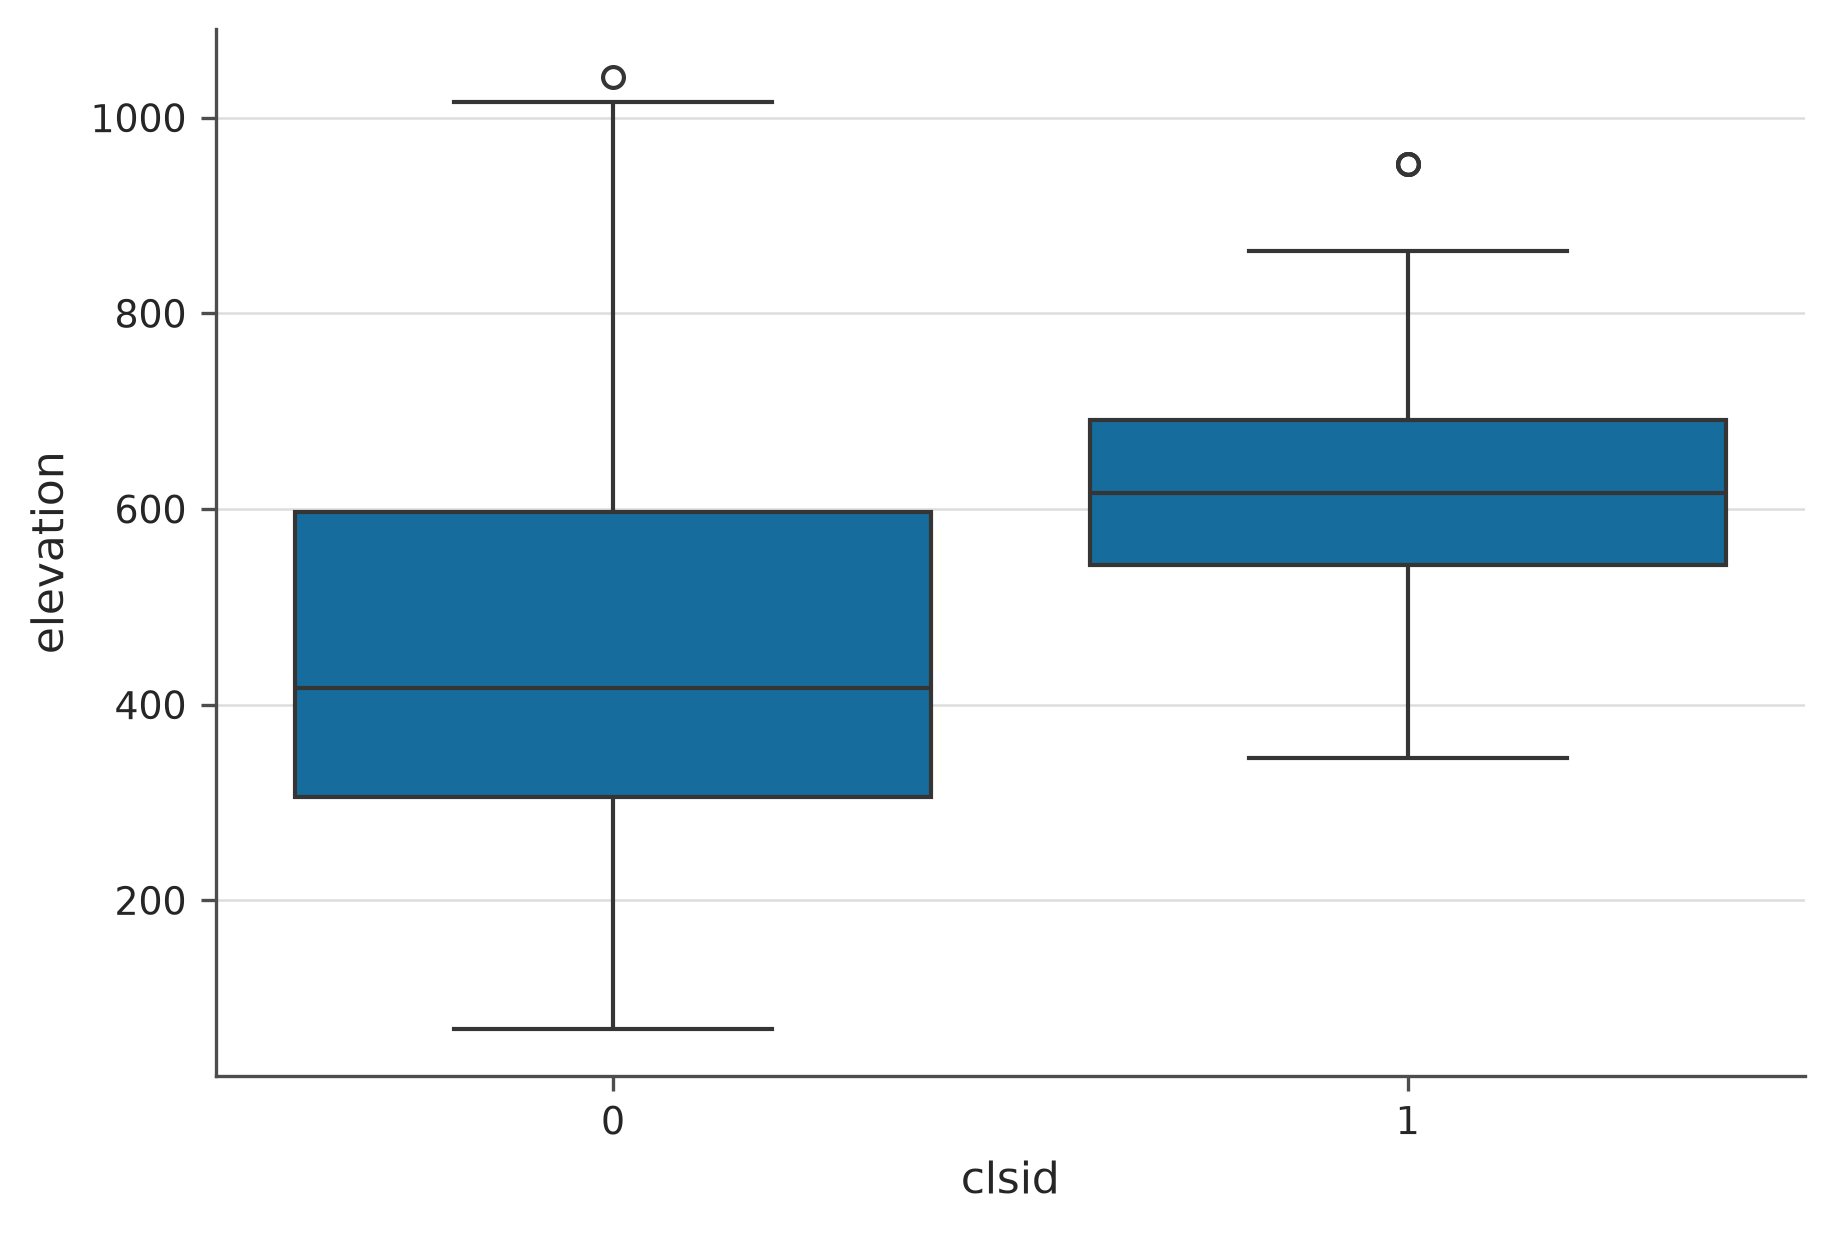

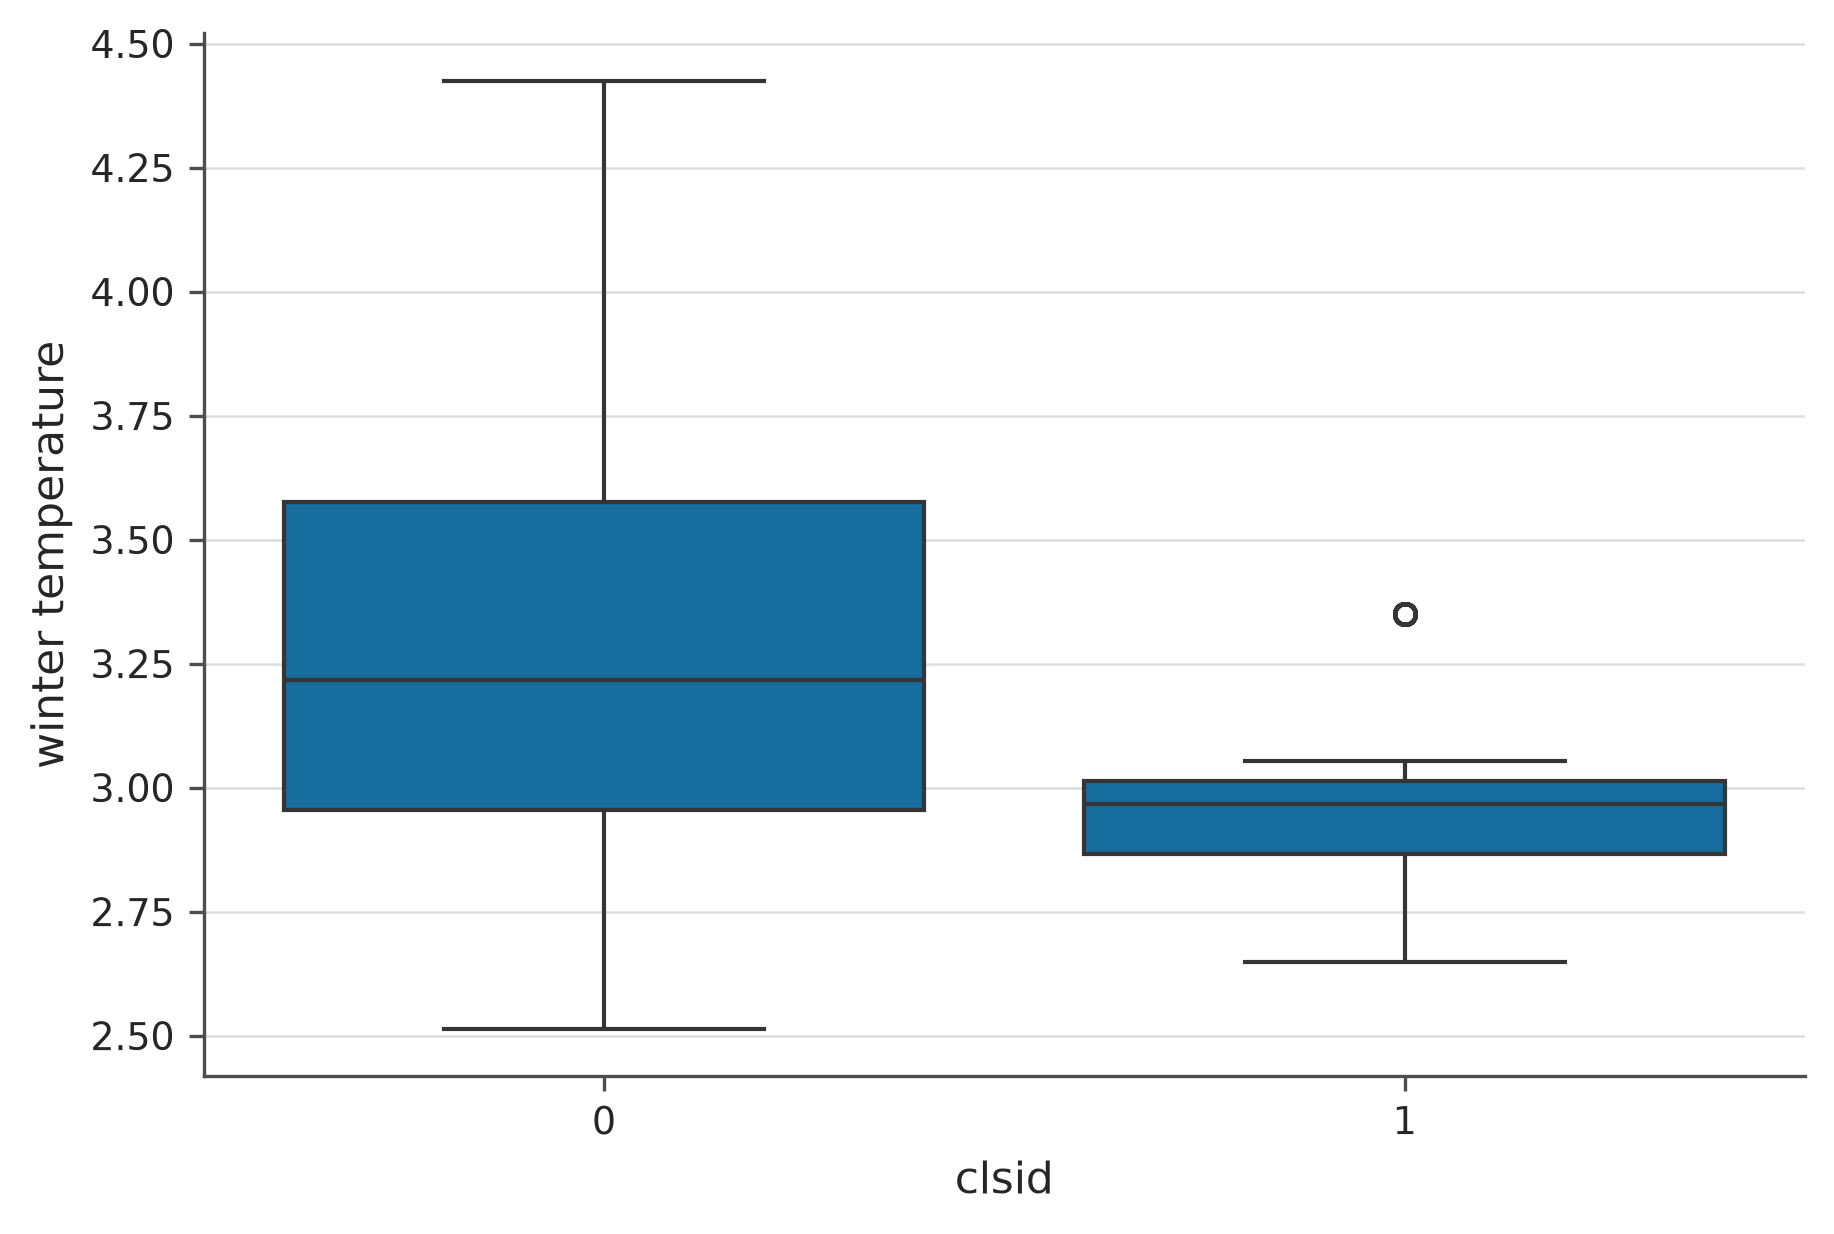

In [12]:
boxplots_dir = os.path.join(out_dir, "boxplots")
species_distribution.comparison_box_plots(
    env_vars=env_vars,
    vec_file=pres_abs_vec_file,
    vec_lyr=pres_abs_vec_lyr,
    out_dir=boxplots_dir,
    cls_col="clsid",
    box_plots=True,
)
box_plot_files = sorted(glob.glob(os.path.join(boxplots_dir, "*.png")))
print(f"{len(box_plot_files)} plots created")
for plot_file in box_plot_files:
    if ("elevation" in plot_file) or ("winter" in plot_file):
        display(Image(filename=plot_file, width=400))

## 7. Calculate the Correlation Matrix

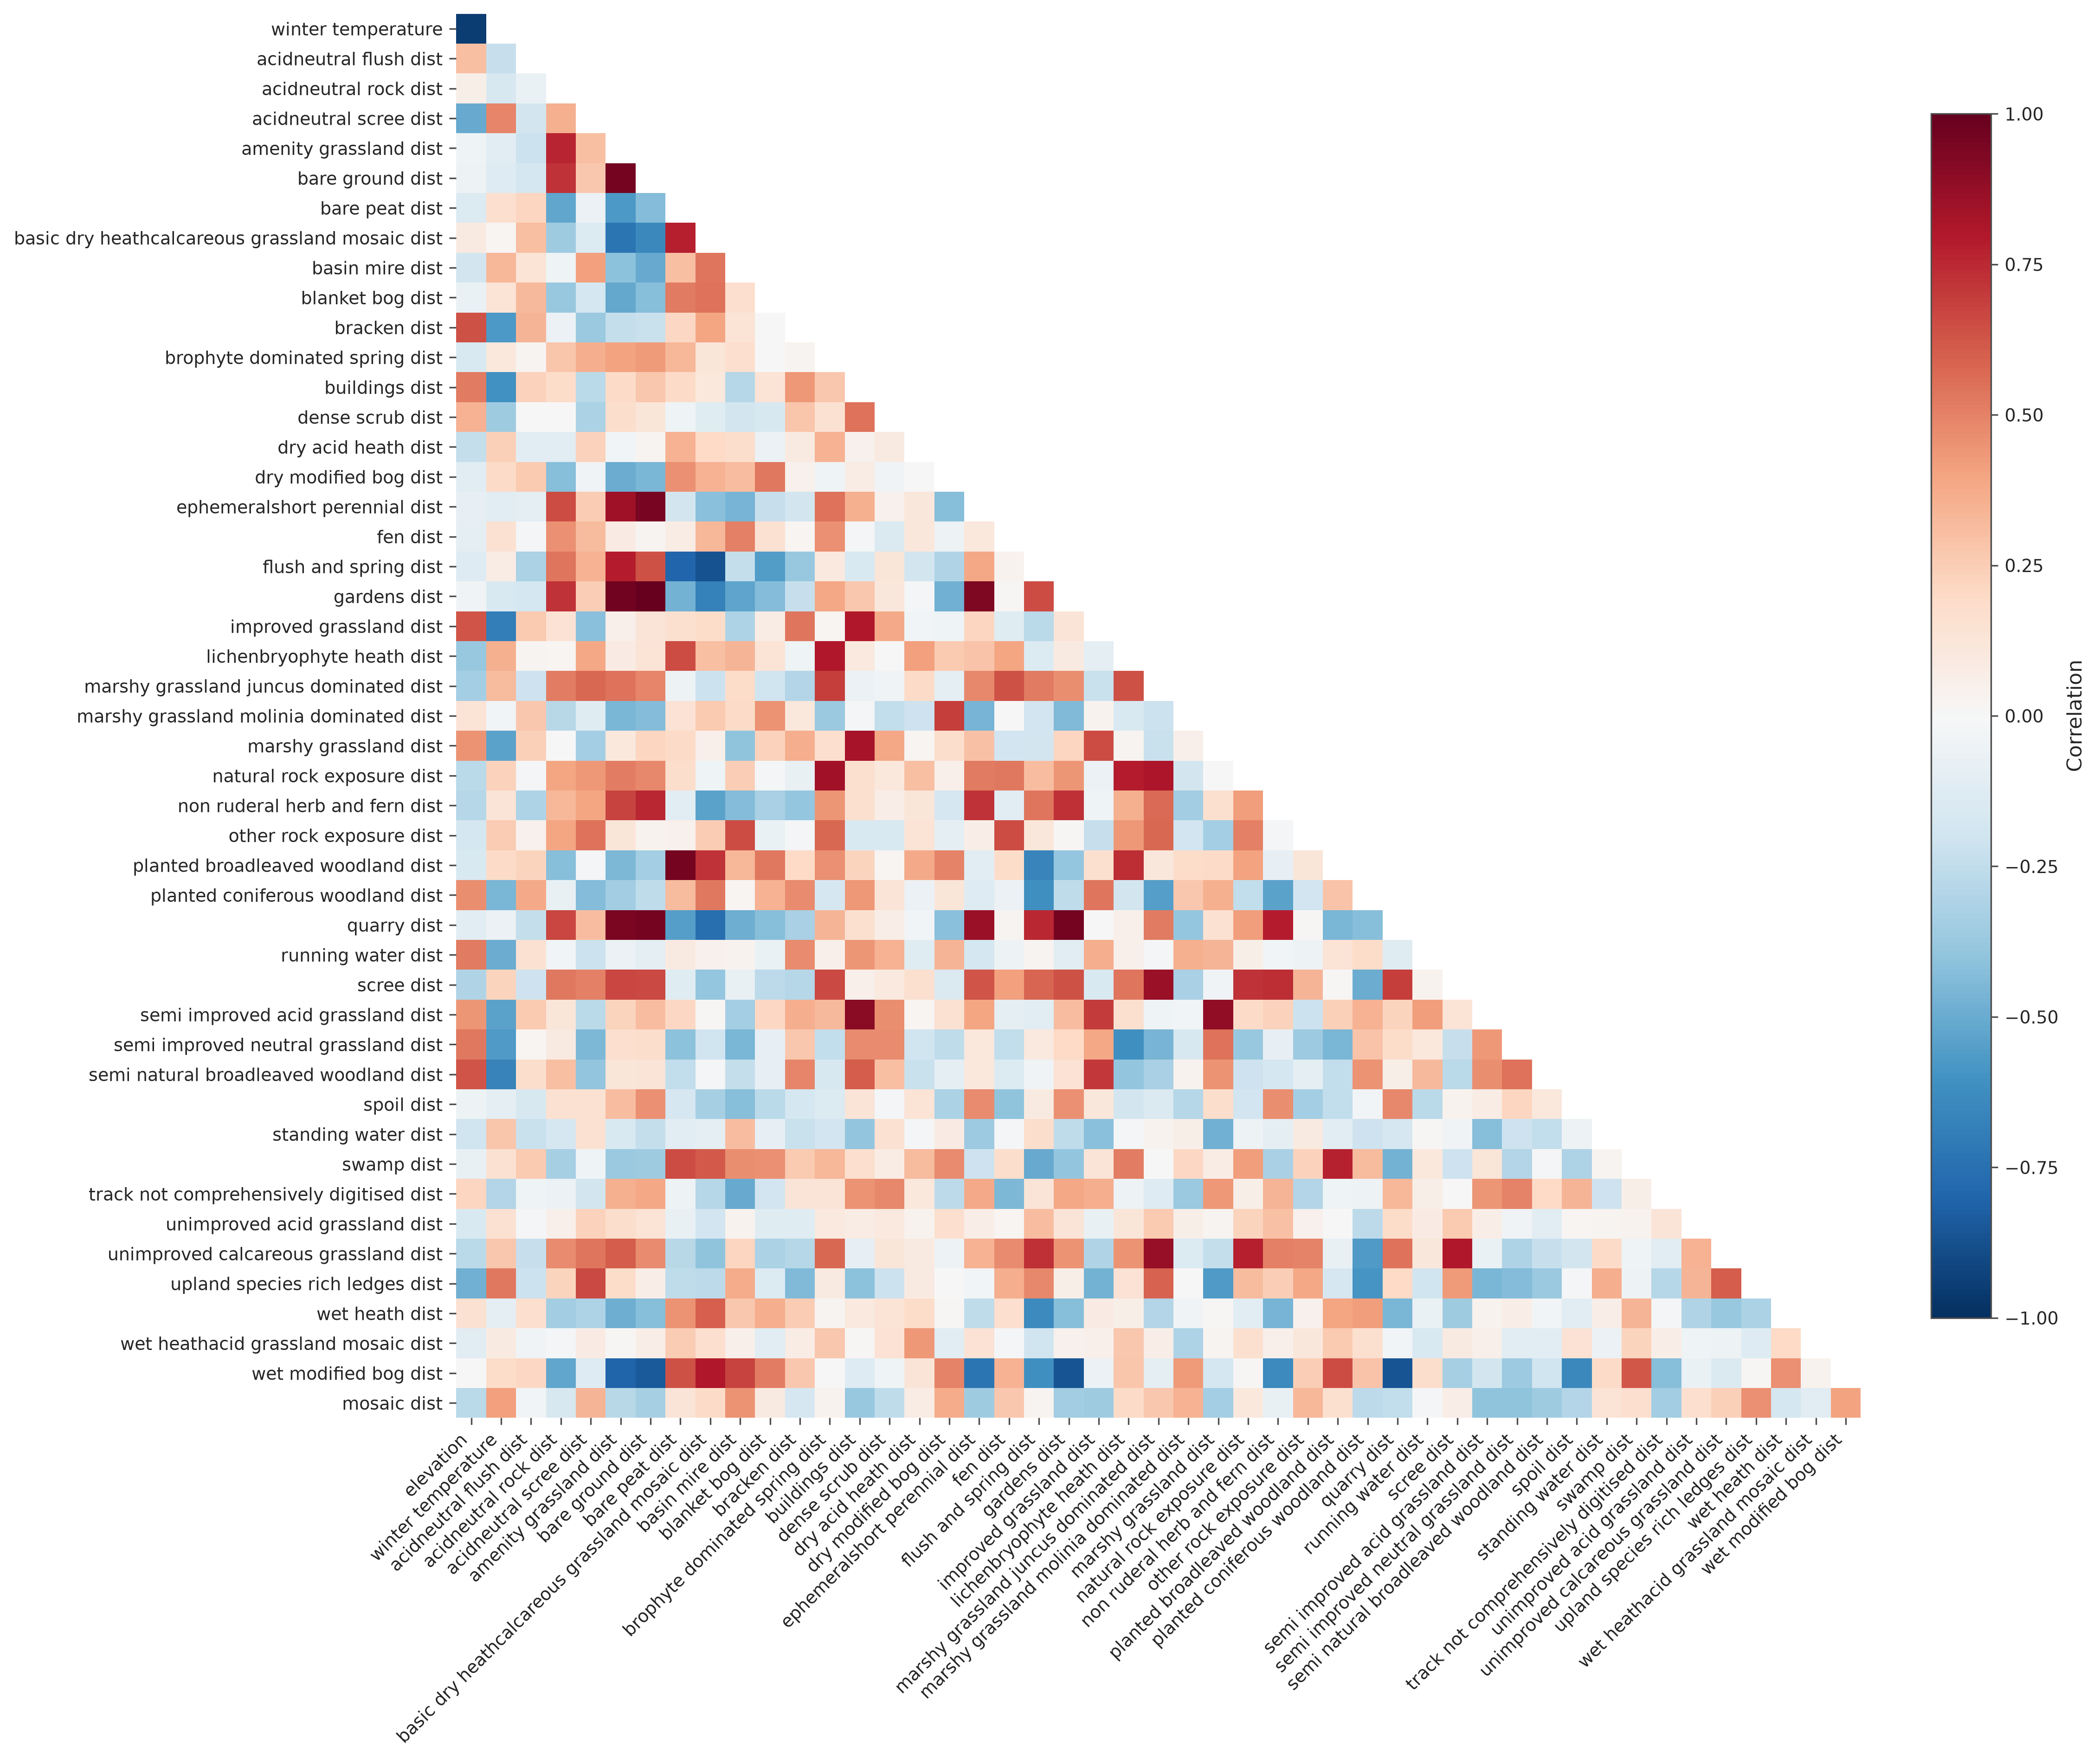

Correlation of elevation and winter temperature: -0.946


In [13]:
corr_df = species_distribution.correlation_matrix(
    env_vars=env_vars,
    vec_file=pres_abs_vec_file,
    vec_lyr=pres_abs_vec_lyr,
    out_corr_file=os.path.join(out_dir, "correlation_matrix.csv"),
    out_plt_file=os.path.join(out_dir, "correlation_matrix.png"),
)
display(Image(filename=os.path.join(out_dir, "correlation_matrix.png"), width=800))
print(f"Correlation of elevation and winter temperature: {corr_df.loc['elevation', 'winter temperature']:.3f}")

## 8. Remove Correlated Variables

Note that removing highly correlated variables can improve the outputs.

In this case, you can see that elevation and winter temperature are highly negatively correlated and therefore one should be removed. We'll remove 'elevation'.

In [14]:
analysis_vars.remove("elevation")

## 9. Standardise Environmental Variables

Some models (e.g., SVM and Logistic Regression) require that the variables are standardised to the same range. However, if you are using a model such as Random Forests you do not need to worry about this step.

`pop_normalise_coeffs` stores the mean and standard deviation of each variable in its `EnvVarInfo` object, so the same standardisation can be applied to the images when the model is applied (`normalise_data=True` below).

In [15]:
# Optionally: Standardise the continuous data using mean and stdev from sample data
species_distribution.pop_normalise_coeffs(
    env_vars=env_vars,
    vec_file=pres_abs_vec_file,
    vec_lyr=pres_abs_vec_lyr,
)
print(env_vars["winter temperature"])

winter temperature: ../data/sdm/environmental_data/Mean_Winter_Temp.tif (Band: 1) (Type: Continuous) (Range: 0, 10) (Normalisation: (x - 3.2521532466094127) / 0.4161774271021896)


In [16]:
pres_abs_std_vec_lyr = "presences_absences_env_var_vld_std"
pres_abs_std_vec_file = os.path.join(out_dir, f"{pres_abs_std_vec_lyr}.gpkg")
species_distribution.apply_normalise_coeffs(
    env_vars=env_vars,
    vec_file=pres_abs_vec_file,
    vec_lyr=pres_abs_vec_lyr,
    out_vec_file=pres_abs_std_vec_file,
    out_vec_lyr=pres_abs_std_vec_lyr,
    out_format="GPKG",
)

## 10. Create Training and Testing Datasets

80 % of each class is used for training and 20 % for testing.

In [17]:
pres_abs_std_train_vec_lyr = "presences_absences_env_var_vld_std_train"
pres_abs_std_train_vec_file = os.path.join(
    out_dir, f"{pres_abs_std_train_vec_lyr}.gpkg"
)
pres_abs_std_test_vec_lyr = "presences_absences_env_var_vld_std_test"
pres_abs_std_test_vec_file = os.path.join(out_dir, f"{pres_abs_std_test_vec_lyr}.gpkg")
species_distribution.create_train_test_sets(
    vec_file=pres_abs_std_vec_file,
    vec_lyr=pres_abs_std_vec_lyr,
    train_vec_file=pres_abs_std_train_vec_file,
    train_vec_lyr=pres_abs_std_train_vec_lyr,
    test_vec_file=pres_abs_std_test_vec_file,
    test_vec_lyr=pres_abs_std_test_vec_lyr,
    split_prop=0.8,
    cls_col="clsid",
    out_format="GPKG",
    rnd_seed=42,
)

## 11. Find Optimal Model Parameters (GridSearch)

The scikit-learn `GridSearchCV` object tests every combination of the parameters in `grid_space` with 5-fold cross-validation (96 combinations, 480 fits; logistic regression is quick to fit). The best parameters are saved to a JSON file.

In [18]:
lr = LogisticRegression(
    solver="liblinear",
    max_iter=500,
    penalty="l2",
    tol=0.0001,
    C=0.1,
    fit_intercept=True,
    intercept_scaling=1,
)
grid_space = {
    "max_iter": [100, 250, 500, 750],
    "penalty": ["l1", "l2"],
    "C": [0.1, 0.5, 1, 1.5],
    "tol": [0.001, 0.0001, 0.0005],
}
search_obj = GridSearchCV(lr, param_grid=grid_space, cv=5, scoring="accuracy", verbose=1)
opt_skl_mdl, opt_mdl_params = species_distribution.search_mdl_params(
    search_obj=search_obj,
    train_vec_file=pres_abs_std_train_vec_file,
    train_vec_lyr=pres_abs_std_train_vec_lyr,
    analysis_vars=analysis_vars,
    cls_col="clsid",
)
mdl_params_file = os.path.join(out_dir, "lr_mdl_params.json")
rsgispy.tools.jsonio.write_dict_to_json(opt_mdl_params, mdl_params_file)
opt_mdl_params

Fitting 5 folds for each of 96 candidates, totalling 480 fits


Best score was 0.9664804469273743 and has parameters {'C': 1.5, 'max_iter': 100, 'penalty': 'l2', 'tol': 0.001}.


{'C': 1.5, 'max_iter': 100, 'penalty': 'l2', 'tol': 0.001}

## 12. Train a Single Model to Explore Fit

`fit_sklearn_mdl` fits the model and returns the training and testing accuracies and the test ROC AUC (it can also save a plot of the ROC curve, `roc_curve_plot`). To draw the ROC curve in the notebook we predict the presence probability of the test points and use `calc_binary_roc_auc` and `plot_roc_curve`.

In [19]:
mdl_params = rsgispy.tools.jsonio.read_json_to_dict(mdl_params_file)
skl_mdl = LogisticRegression(
    solver="liblinear", fit_intercept=True, intercept_scaling=1, **mdl_params
)
skl_mdl, train_acc, test_acc, roc_auc = species_distribution.fit_sklearn_mdl(
    est_cls_obj=skl_mdl,
    train_vec_file=pres_abs_std_train_vec_file,
    train_vec_lyr=pres_abs_std_train_vec_lyr,
    test_vec_file=pres_abs_std_test_vec_file,
    test_vec_lyr=pres_abs_std_test_vec_lyr,
    analysis_vars=analysis_vars,
    cls_col="clsid",
    return_model=True,
)
print(f"Train: {train_acc}")
print(f"Test: {test_acc}")
print(f"Test AUC: {roc_auc}")

Classifier Train Score = 97.54%
Classifier Test Score = 96.88%
Train: 0.9754189944134078
Test: 0.96875
Test AUC: 0.9675


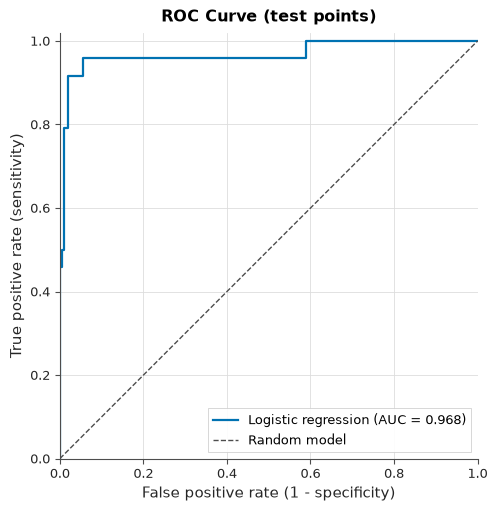

In [20]:
test_gdf = geopandas.read_file(
    pres_abs_std_test_vec_file, layer=pres_abs_std_test_vec_lyr
)
test_probs = skl_mdl.predict_proba(test_gdf[analysis_vars])[:, 1]
fpr, tpr, test_auc = species_distribution.calc_binary_roc_auc(test_gdf["clsid"], test_probs)
fig, ax = species_distribution.plot_roc_curve(
    fpr,
    tpr,
    test_auc,
    label="Logistic regression",
    title="ROC Curve (test points)",
    out_plot_file=os.path.join(out_dir, "lr_testing_roc_curve.png"),
)

## 13. Jackknife Environmental Variable Importance

Each variable is in turn left out of the model, and used on its own, and the change in test AUC and accuracy recorded: a variable whose removal reduces the AUC most, or which gives a high AUC on its own, is important.

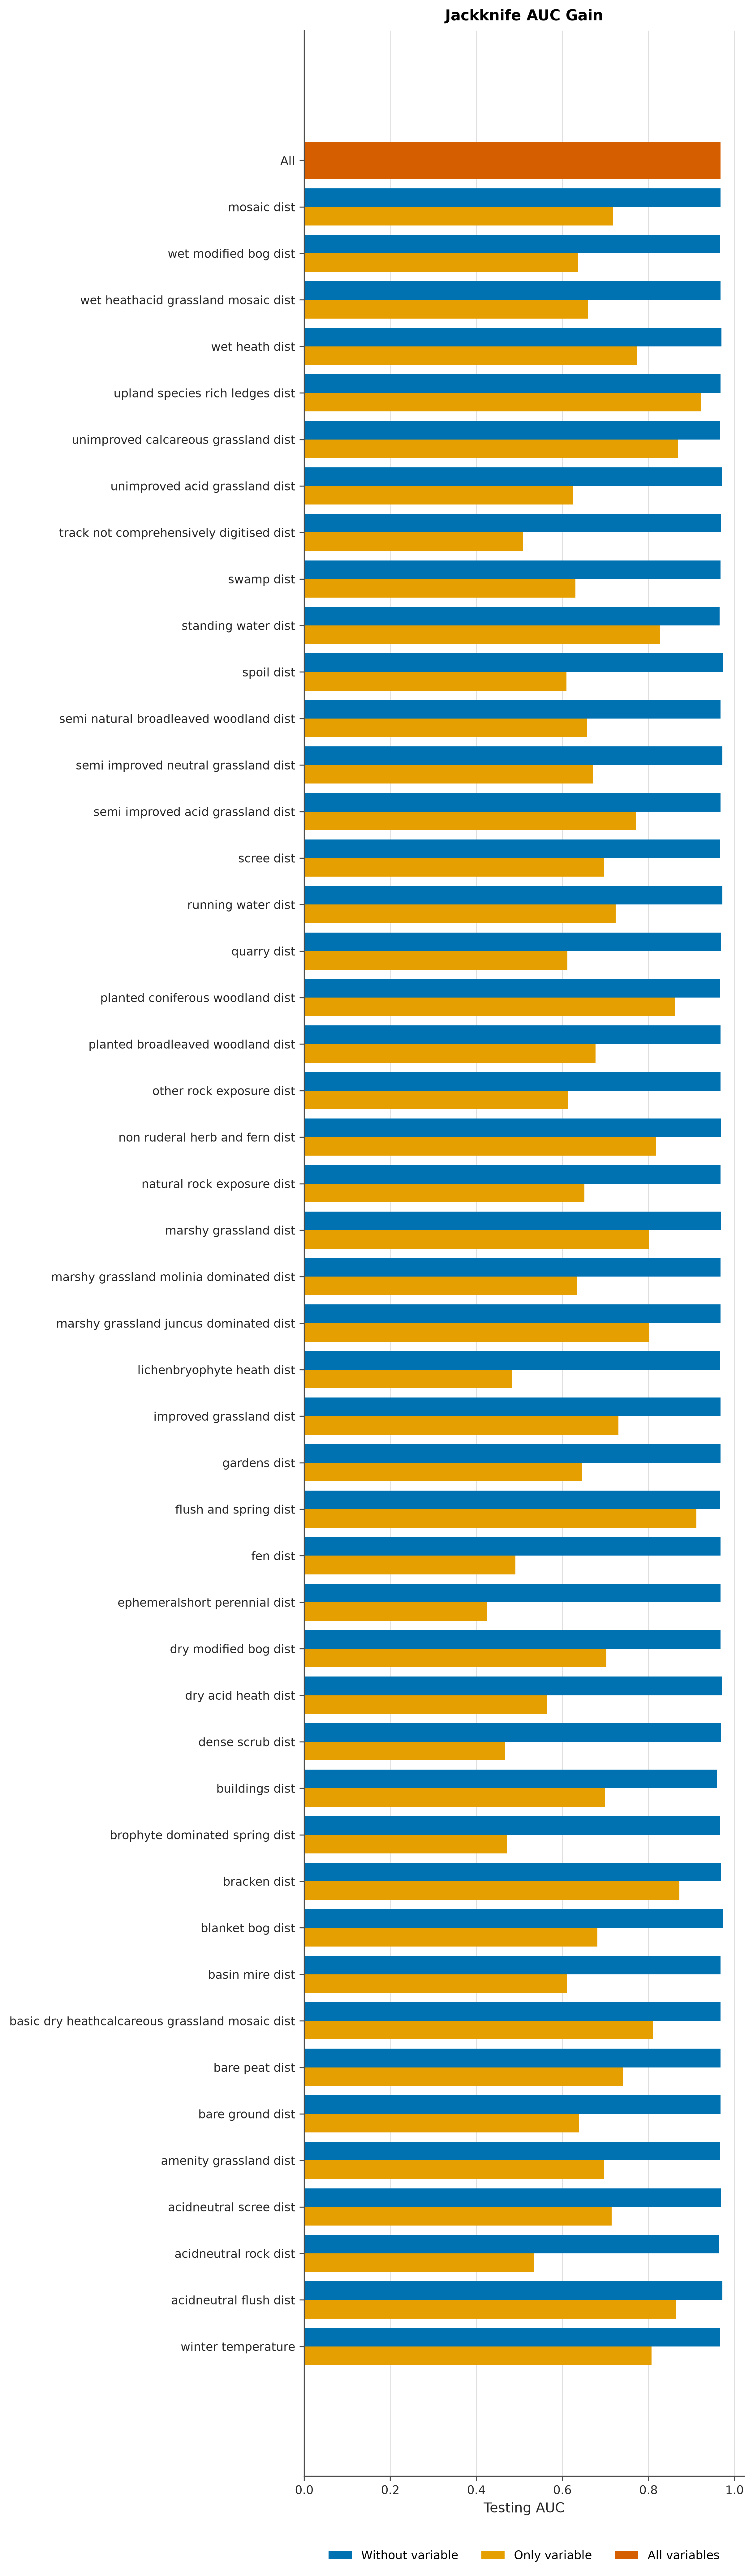

In [21]:
# Create parameterised but untrained model for jackknife tests
# as it will be cloned and trained multiple times and without
# being untrained the analysis will not produce reliable results
skl_utrain_mdl = LogisticRegression(
    solver="liblinear", fit_intercept=True, intercept_scaling=1, **mdl_params
)
jk_df = species_distribution.sklearn_jackknife_var_importance(
    est_cls_obj=skl_utrain_mdl,
    train_vec_file=pres_abs_std_train_vec_file,
    train_vec_lyr=pres_abs_std_train_vec_lyr,
    test_vec_file=pres_abs_std_test_vec_file,
    test_vec_lyr=pres_abs_std_test_vec_lyr,
    analysis_vars=analysis_vars,
    out_var_importance_file=os.path.join(out_dir, "jackknife_var_importance.csv"),
    out_importance_auc_plot=os.path.join(
        out_dir, "jackknife_var_importance_auc_plot.png"
    ),
    out_importance_test_plot=os.path.join(
        out_dir, "jackknife_var_importance_test_plot.png"
    ),
    cls_col="clsid",
    use_pbar=False,
)
display(Image(filename=os.path.join(out_dir, "jackknife_var_importance_auc_plot.png"), width=800))

## 14. Environmental Variable Response Curves

winter temperature Range:	(-1.773477505430513 - 2.8179972921874663): Mean = -0.6832329514783559
Calculating Response Curve for 'winter temperature'
acidneutral flush dist Range:	(-1.3991436378740243 - 3.644324356440007): Mean = 1.122444131655858
Calculating Response Curve for 'acidneutral flush dist'
acidneutral rock dist Range:	(-1.7198018968753777 - 2.8039208577915704): Mean = -0.20899120163971496
Calculating Response Curve for 'acidneutral rock dist'
acidneutral scree dist Range:	(-1.3932118270912686 - 3.1570017749936743): Mean = -0.5796678931811013
Calculating Response Curve for 'acidneutral scree dist'
amenity grassland dist Range:	(-1.6493129603866123 - 2.2623222400638086): Mean = -0.6124792760001843
Calculating Response Curve for 'amenity grassland dist'
bare ground dist Range:	(-1.9712137499276385 - 2.325385485118349): Mean = -0.30948258235214
Calculating Response Curve for 'bare ground dist'
bare peat dist Range:	(-2.3628259793857507 - 2.281487341611497): Mean = 0.778739031770

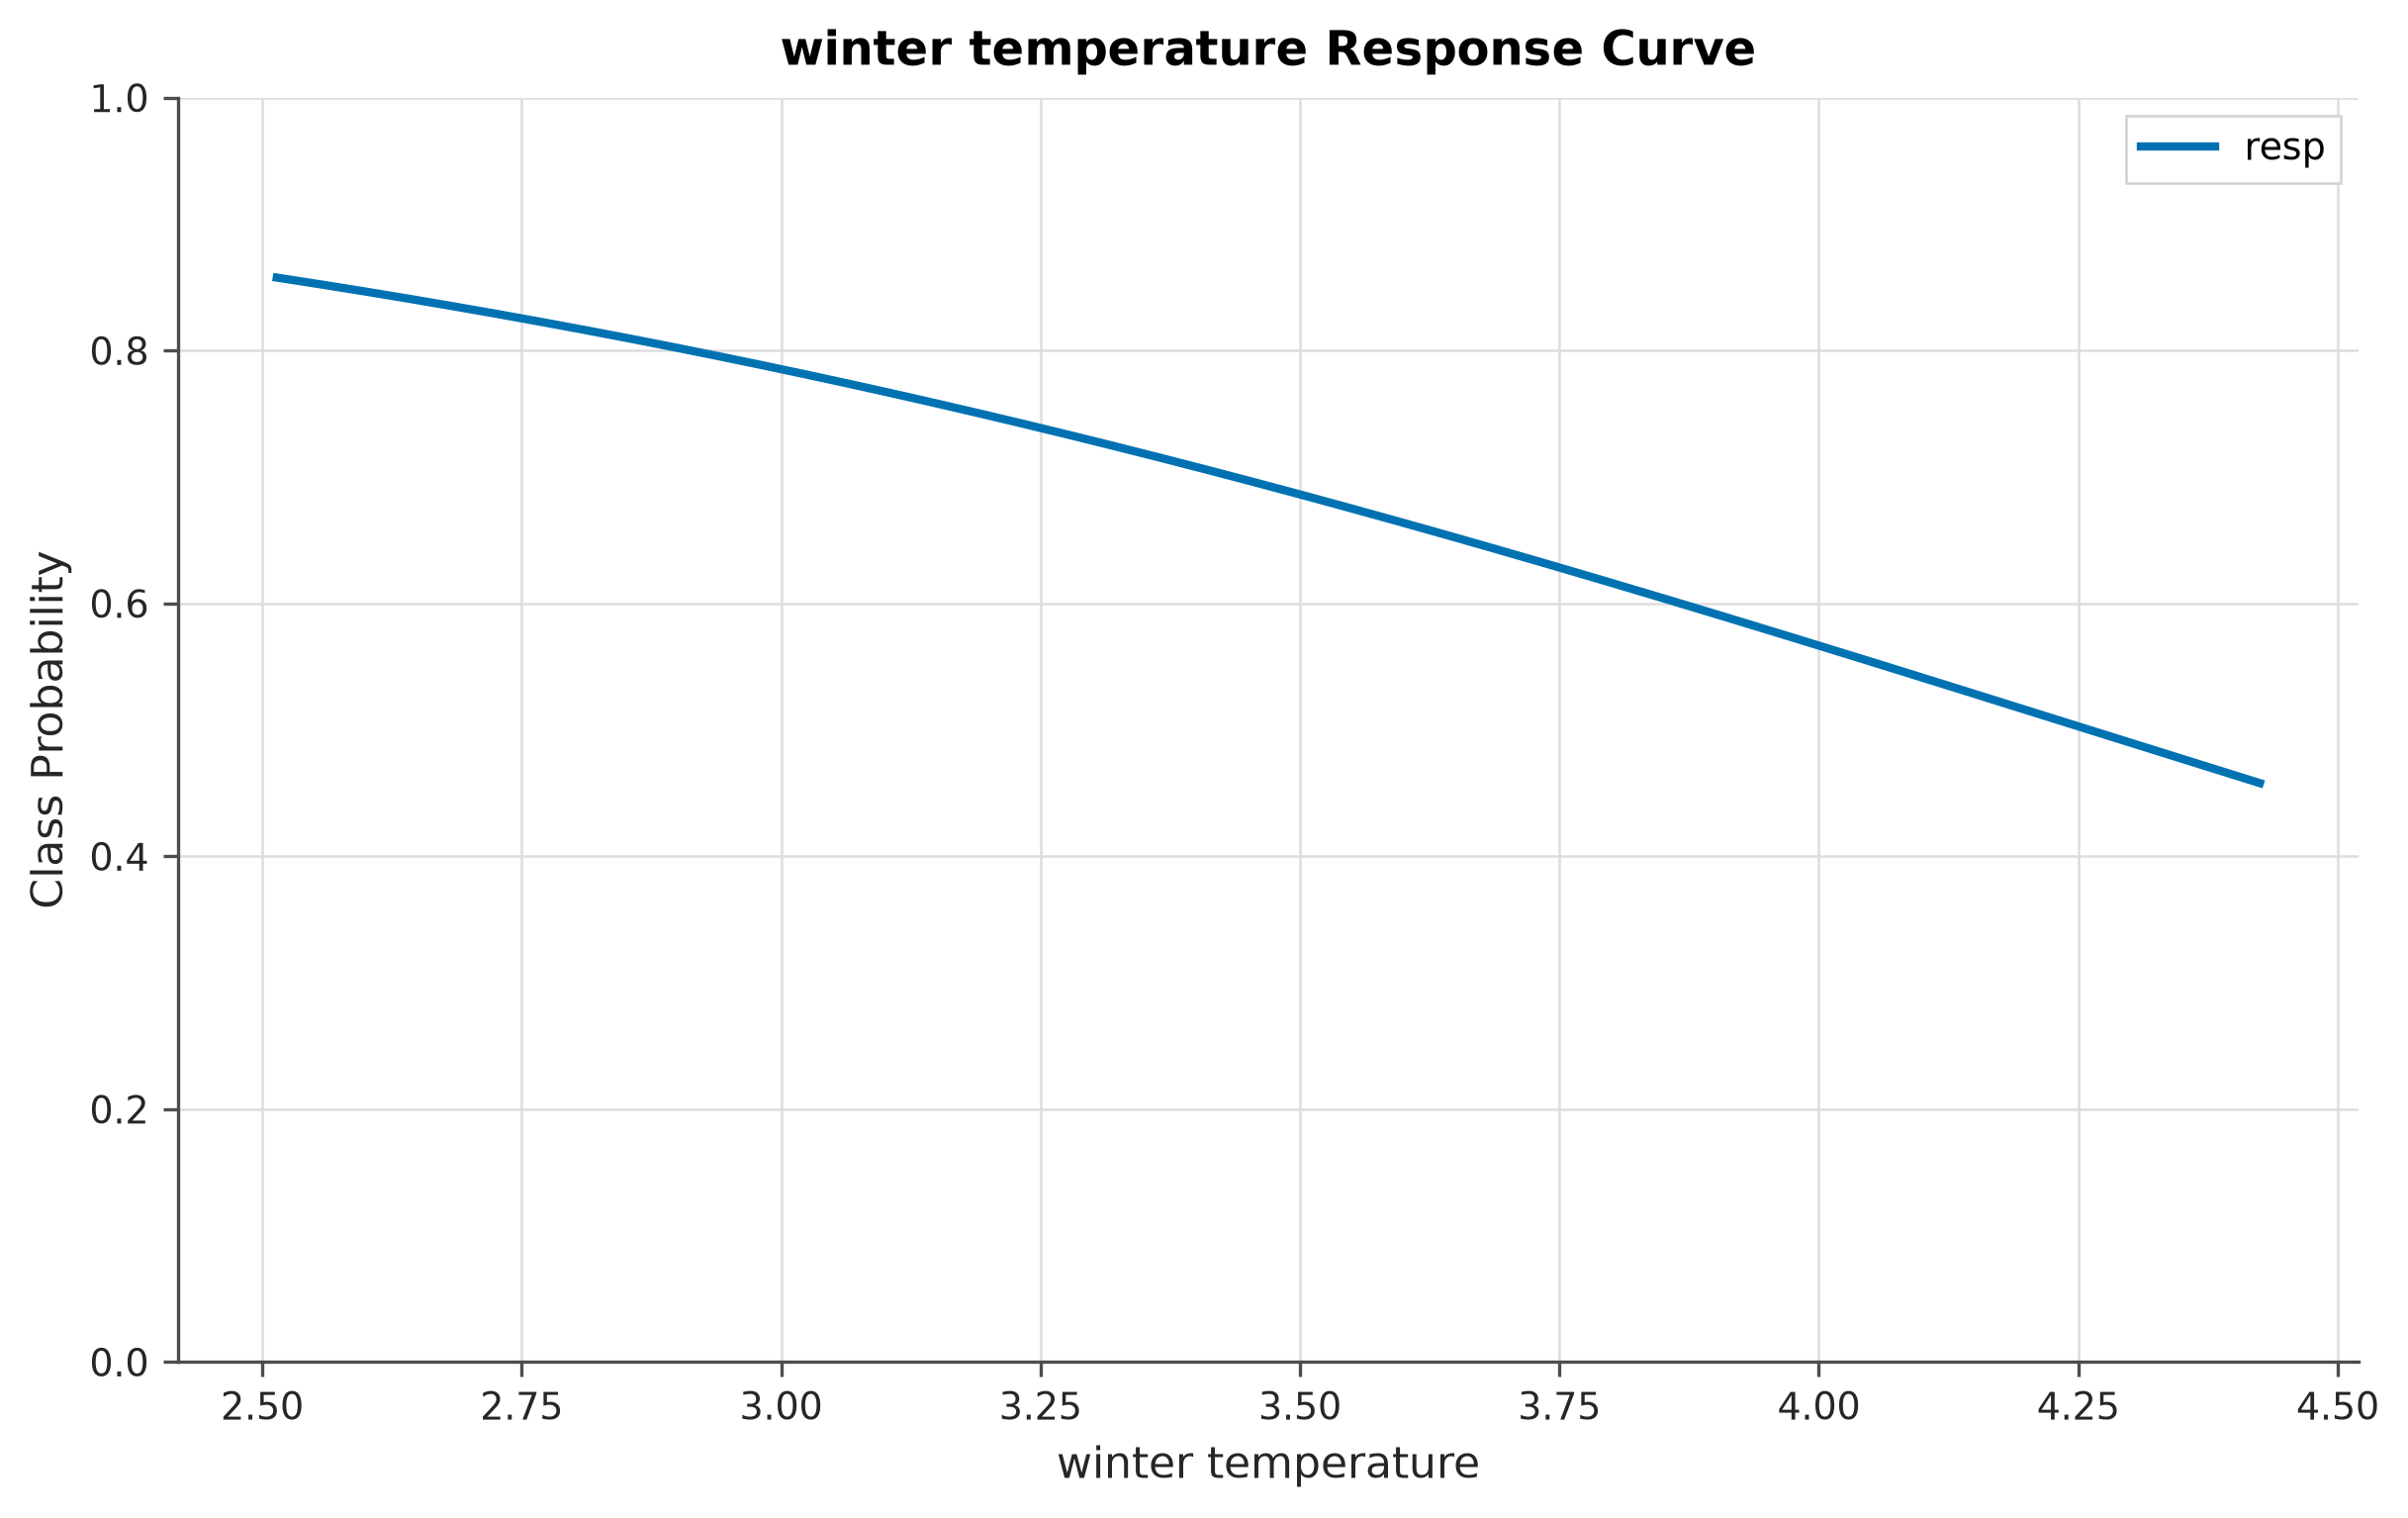

In [22]:
resp_plots_dir = os.path.join(out_dir, "var_response_curves")
resp_df = species_distribution.sklearn_mdl_variable_response_curves(
    est_cls_obj=skl_mdl,
    train_vec_file=pres_abs_std_train_vec_file,
    train_vec_lyr=pres_abs_std_train_vec_lyr,
    analysis_vars=analysis_vars,
    output_file=os.path.join(out_dir, "var_response_curve_data.csv"),
    response_plots_dir=resp_plots_dir,
    n_samples=1000,
    cls_col="clsid",
    normalised_data=True,
    env_vars=env_vars,
)
resp_plot_files = sorted(glob.glob(os.path.join(resp_plots_dir, "*.png")))
for plot_file in resp_plot_files:
    if "winter" in plot_file:
        display(Image(filename=plot_file, width=500))

## 15. SHAP Model Explainer

SHAP (SHapley Additive exPlanations) values show the contribution of each variable to each prediction. This needs the optional `shap` package; if it is not installed the step is skipped.

In [23]:
if importlib.util.find_spec("shap") is not None:
    species_distribution.shap_sklearn_mdl_explainer(
        est_cls_obj=skl_mdl,
        train_vec_file=pres_abs_std_train_vec_file,
        train_vec_lyr=pres_abs_std_train_vec_lyr,
        analysis_vars=analysis_vars,
        shap_summary_plot=os.path.join(out_dir, "shap_summary_plot.png"),
        shap_heatmap_plot=os.path.join(out_dir, "shap_heatmap.png"),
        shap_scatter_plots_dir=os.path.join(out_dir, "shap_scatter_plots"),
        shap_depend_plots_dir=os.path.join(out_dir, "shap_dependence_plots"),
        subsample_n_smpls=None,
        use_tree_explainer=False,
        use_linear_explainer=True,
    )
    display(Image(filename=os.path.join(out_dir, "shap_summary_plot.png"), width=700))
else:
    print("The shap package is not installed, so the SHAP analysis is skipped.")

The shap package is not installed, so the SHAP analysis is skipped.


## 16. Model Sensitivity Analysis

A Sobol sensitivity analysis (using the `SALib` package) measures how much of the variance of the model output is due to each variable, alone (first order) and including its interactions (total). The number of samples should be a power of 2.

`salib_sklearn_mdl_sensitivity` saves a plot of all the indices (`sobol_plot_file`), but with this many variables (and over 1000 pairs of variables for the second order indices) it is hard to read, so here we plot the total and first order indices of the 15 most sensitive variables with `rsgispy.tools.plotting.plot_feature_importance_bars`, with the confidence intervals as error bars.

winter temperature Range:	(-1.773477505430513 - 2.8179972921874663)
acidneutral flush dist Range:	(-1.3991436378740243 - 3.644324356440007)
acidneutral rock dist Range:	(-1.7198018968753777 - 2.8039208577915704)
acidneutral scree dist Range:	(-1.3932118270912686 - 3.1570017749936743)
amenity grassland dist Range:	(-1.6493129603866123 - 2.2623222400638086)
bare ground dist Range:	(-1.9712137499276385 - 2.325385485118349)
bare peat dist Range:	(-2.3628259793857507 - 2.281487341611497)
basic dry heathcalcareous grassland mosaic dist Range:	(-1.3673180823858115 - 2.823649030784386)
basin mire dist Range:	(-1.819028007540416 - 2.821082478063189)
blanket bog dist Range:	(-1.5003179422825952 - 2.829634210798031)
bracken dist Range:	(-1.2762492403158083 - 3.215088748039631)
brophyte dominated spring dist Range:	(-1.6390563187731382 - 3.4442172545923113)
buildings dist Range:	(-1.6223458793482488 - 3.8411507950277626)
dense scrub dist Range:	(-1.928715389098019 - 3.5527587845087965)
dry acid he

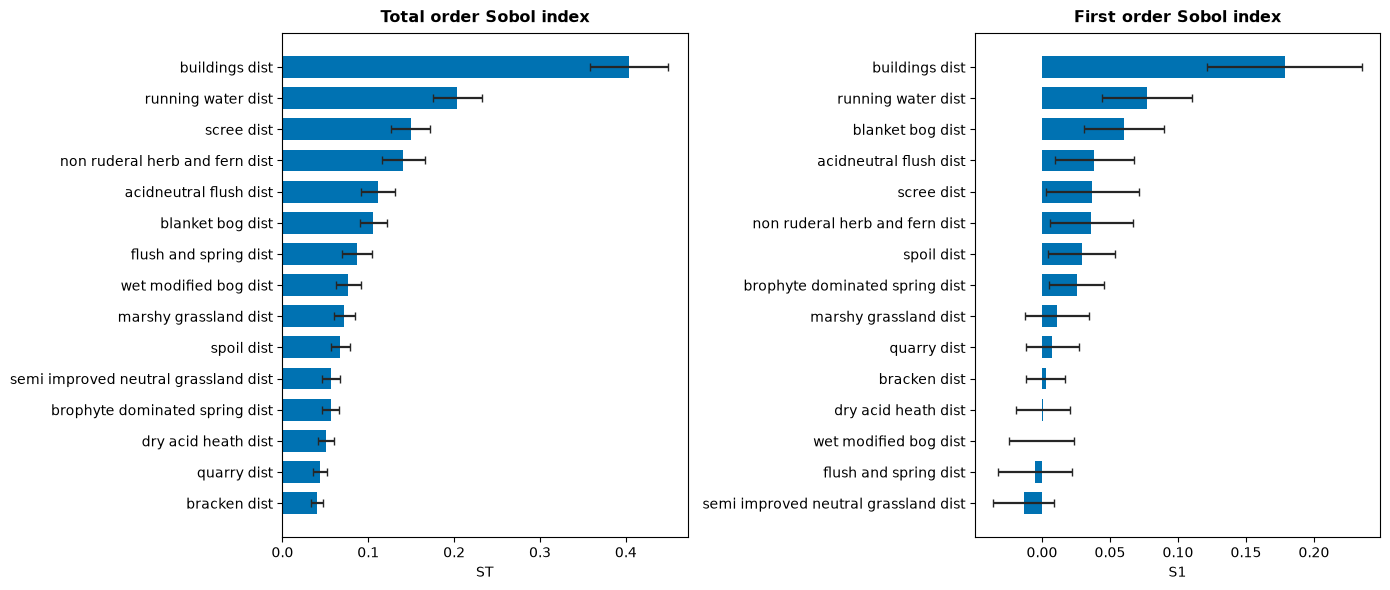

In [24]:
total_si, first_si, second_si = species_distribution.salib_sklearn_mdl_sensitivity(
    est_cls_obj=skl_mdl,
    train_vec_file=pres_abs_std_train_vec_file,
    train_vec_lyr=pres_abs_std_train_vec_lyr,
    analysis_vars=analysis_vars,
    n_samples=1024,
    sobol_plot_file=os.path.join(out_dir, "sobol_sa_plot.png"),
    sobol_overall_file=os.path.join(out_dir, "sobol_sa_overall.csv"),
    sobol_first_file=os.path.join(out_dir, "sobol_sa_first_order.csv"),
    sobol_second_file=os.path.join(out_dir, "sobol_sa_second_order.csv"),
)
top_vars = total_si["ST"].sort_values(ascending=False).index[:15]
fig, axs = plt.subplots(1, 2, figsize=(14, 6), sharey=False)
_ = rsgispy.tools.plotting.plot_feature_importance_bars(
    list(top_vars),
    total_si.loc[top_vars, "ST"],
    errors=total_si.loc[top_vars, "ST_conf"],
    title="Total order Sobol index",
    xlabel="ST",
    ax=axs[0],
)
_ = rsgispy.tools.plotting.plot_feature_importance_bars(
    list(top_vars),
    first_si.loc[top_vars, "S1"],
    errors=first_si.loc[top_vars, "S1_conf"],
    title="First order Sobol index",
    xlabel="S1",
    ax=axs[1],
)
fig.tight_layout()

## 17. Create Ensemble of Models

Using a k-fold analysis a set of models are created with different subsets of the training data (by default each model is fitted to a random 60 % of the training data).

In [25]:
skl_mdl = LogisticRegression(
    solver="liblinear", fit_intercept=True, intercept_scaling=1, **mdl_params
)

skl_mdls = species_distribution.fit_kfold_sklearn_mdls(
    est_cls_obj=skl_mdl,
    train_vec_file=pres_abs_std_train_vec_file,
    train_vec_lyr=pres_abs_std_train_vec_lyr,
    test_vec_file=pres_abs_std_test_vec_file,
    test_vec_lyr=pres_abs_std_test_vec_lyr,
    analysis_vars=analysis_vars,
    n_kfolds=25,
    cls_col="clsid",
    rnd_seed=42,
    use_pbar=False,
)

ROC: 0.9495833333333333 - 0.9645833333333333 - 0.9747916666666667
Train: 0.9553072625698324 - 0.9757914338919925 - 0.9869646182495344
Test: 0.9464285714285714 - 0.9642857142857143 - 0.9776785714285714


## 18. Create an SDM Output Summarising Hard Classification

This first analysis runs the ensemble of classifiers producing a set of hard (binary) classifications which are then summarised as a proportion of classifications which are mapped as presence.

In [26]:
out_cls_img = os.path.join(out_dir, "Snowdon_Beetle_sdm_cls_prob.tif")

species_distribution.pred_ensemble_sklearn_mdls_cls(
    est_cls_objs=skl_mdls,
    in_msk_img=study_site_msk_img,
    img_msk_val=1,
    env_vars=env_vars,
    analysis_vars=analysis_vars,
    output_img=out_cls_img,
    gdalformat="GTIFF",
    tmp_dir=tmp_dir,
    normalise_data=True,
    calc_stats=True,
    use_pbar=False,
)

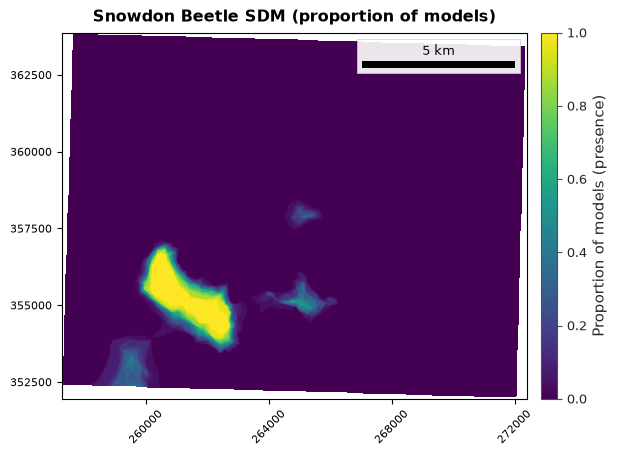

In [27]:
# Create a plot using the matplotlib library
fig, ax = plt.subplots(figsize=(6, 5))

im = rsgispy.mapping.raster.create_raster_cmap_img_map(
    ax,
    input_img=out_cls_img,
    img_band=1,
    title_str="Snowdon Beetle SDM (proportion of models)",
    show_colour_bar=True,
    cbar_label="Proportion of models (presence)",
)
ax.tick_params(axis="x", labelrotation=45)

## 19. Create an SDM Output Summarising Model Probability Outputs

This second analysis runs the ensemble of classifiers producing a probability output which are then summarised as the median probability from all the models.

In [28]:
out_prob_img = os.path.join(out_dir, "Snowdon_Beetle_sdm_med_prob.tif")

species_distribution.pred_ensemble_sklearn_mdls_prob(
    est_cls_objs=skl_mdls,
    in_msk_img=study_site_msk_img,
    img_msk_val=1,
    env_vars=env_vars,
    analysis_vars=analysis_vars,
    output_img=out_prob_img,
    gdalformat="GTIFF",
    tmp_dir=tmp_dir,
    normalise_data=True,
    calc_stats=True,
    use_pbar=False,
)

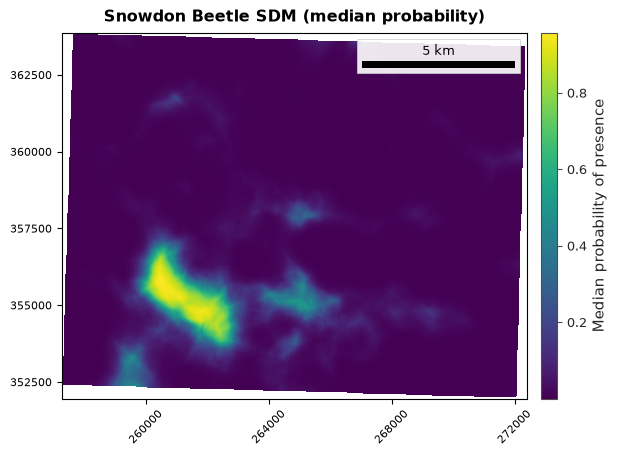

In [29]:
# Create a plot using the matplotlib library
fig, ax = plt.subplots(figsize=(6, 5))

im = rsgispy.mapping.raster.create_raster_cmap_img_map(
    ax,
    input_img=out_prob_img,
    img_band=1,
    title_str="Snowdon Beetle SDM (median probability)",
    show_colour_bar=True,
    cbar_label="Median probability of presence",
)
ax.tick_params(axis="x", labelrotation=45)

To go further (see the rsgispy species distribution modelling guide), you could threshold the probability map into suitable / unsuitable areas (`species_distribution.calc_binary_threshold`), evaluate the ensemble on the test set, use spatial block cross-validation (`rsgispy.ml.cv.SpatialBlockKFold`) or try a Random Forests model.